<a href="https://colab.research.google.com/github/sanyasana1/MN/blob/main/%D0%9B%D0%A04_%D0%9C%D0%9D_%D0%9B%D0%B0%D0%B7%D0%B0%D1%80%D0%B5%D0%BD%D0%BA%D0%BE_3_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [3]:
# 1. Завантаження та первинний аналіз даних
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import warnings
warnings.filterwarnings("ignore")

DATA_URLS = [
    "https://raw.githubusercontent.com/selva86/datasets/master/CarPrice_Assignment.csv",
    "https://raw.githubusercontent.com/plotly/datasets/master/CarPrice_Assignment.csv",
]

df = None
load_errors = []
for url in DATA_URLS:
    try:
        candidate = pd.read_csv(url)
        if "price" in candidate.columns and "car_ID" in candidate.columns:
            df = candidate
            print(f"Дані завантажено з: {url}")
            break
    except Exception as exc:
        load_errors.append(f"{url}: {exc}")

if df is None:
    try:
        from google.colab import files
        print("Автоматичне завантаження не вдалося. Завантажте файл CarPrice_Assignment.csv.")
        uploaded = files.upload()
        csv_name = next((name for name in uploaded if name.lower().endswith(".csv")), None)
        if csv_name is None:
            raise FileNotFoundError("Не знайдено CSV-файл.")
        df = pd.read_csv(csv_name)
    except Exception as exc:
        raise RuntimeError(
            "Не вдалося завантажити датасет. Завантажте CarPrice_Assignment.csv з Kaggle "
            "і повторно виконайте цю комірку."
        ) from exc

print(f"Кількість об'єктів: {df.shape[0]}")
print(f"Кількість ознак: {df.shape[1]}")
print("\nНазви стовпців:")
print(df.columns.tolist())
print("\nТипи даних:")
display(df.dtypes.rename("Тип даних").to_frame())
print("\nЦільова змінна: price")
print("\nОсновні статистичні характеристики:")
display(df.describe(include="all").T)
print("\nПерші 5 рядків:")
display(df.head())

Автоматичне завантаження не вдалося. Завантажте файл CarPrice_Assignment.csv.


Saving CarPrice_Assignment.csv to CarPrice_Assignment (2).csv
Кількість об'єктів: 205
Кількість ознак: 26

Назви стовпців:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Типи даних:


,Тип даних
car_ID,int64
symboling,int64
CarName,object
fueltype,object
aspiration,object
doornumber,object
carbody,object
drivewheel,object
enginelocation,object
wheelbase,float64



Цільова змінна: price

Основні статистичні характеристики:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
car_ID,205.0,NaN,NaN,NaN,103.0,59.322565,1.0,52.0,103.0,154.0,205.0
symboling,205.0,NaN,NaN,NaN,0.834146,1.245307,-2.0,0.0,1.0,2.0,3.0
CarName,205,147,peugeot 504,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fueltype,205,2,gas,185,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aspiration,205,2,std,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
doornumber,205,2,four,115,NaN,NaN,NaN,NaN,NaN,NaN,NaN
carbody,205,5,sedan,96,NaN,NaN,NaN,NaN,NaN,NaN,NaN
drivewheel,205,3,fwd,120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
enginelocation,205,2,front,202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wheelbase,205.0,NaN,NaN,NaN,98.756585,6.021776,86.6,94.5,97.0,102.4,120.9



Перші 5 рядків:


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [4]:
missing = df.isna().sum().sort_values(ascending=False)
print("Пропущені значення за стовпцями:")
display(missing[missing > 0].rename("Кількість пропусків").to_frame()
        if (missing > 0).any() else pd.DataFrame({"Повідомлення": ["Пропущених значень немає."]}))

content_cols = [col for col in df.columns if col != "car_ID"]
duplicate_count = df.duplicated(subset=content_cols).sum()
print(f"\nПовні дублікати за змістовими характеристиками (без car_ID): {duplicate_count}")

print("\nКількість унікальних значень у кожному стовпці:")
display(df.nunique(dropna=False).rename("Кількість унікальних значень").to_frame())

print("\nВисновок:")
if missing.sum() == 0:
    print("Пропущених значень немає.")
else:
    print(f"Виявлено {int(missing.sum())} пропущених значень; їх потрібно врахувати під час передобробки.")
print(f"Знайдено {duplicate_count} змістових дублікатів. car_ID не враховувався, бо є ідентифікатором.")

Пропущені значення за стовпцями:


,Повідомлення
0,Пропущених значень немає.



Повні дублікати за змістовими характеристиками (без car_ID): 0

Кількість унікальних значень у кожному стовпці:


,Кількість унікальних значень
car_ID,205
symboling,6
CarName,147
fueltype,2
aspiration,2
doornumber,2
carbody,5
drivewheel,3
enginelocation,2
wheelbase,53



Висновок:
Пропущених значень немає.
Знайдено 0 змістових дублікатів. car_ID не враховувався, бо є ідентифікатором.


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [5]:
car_ids = df["car_ID"].copy()
data = df.drop(columns=["car_ID"]).copy()

print("car_ID збережено в окремому об'єкті car_ids.")
print(f"Кількість ID: {len(car_ids)}; кількість рядків для моделювання: {len(data)}")
print("car_ID вилучено з таблиці ознак.")

car_ID збережено в окремому об'єкті car_ids.
Кількість ID: 205; кількість рядків для моделювання: 205
car_ID вилучено з таблиці ознак.


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


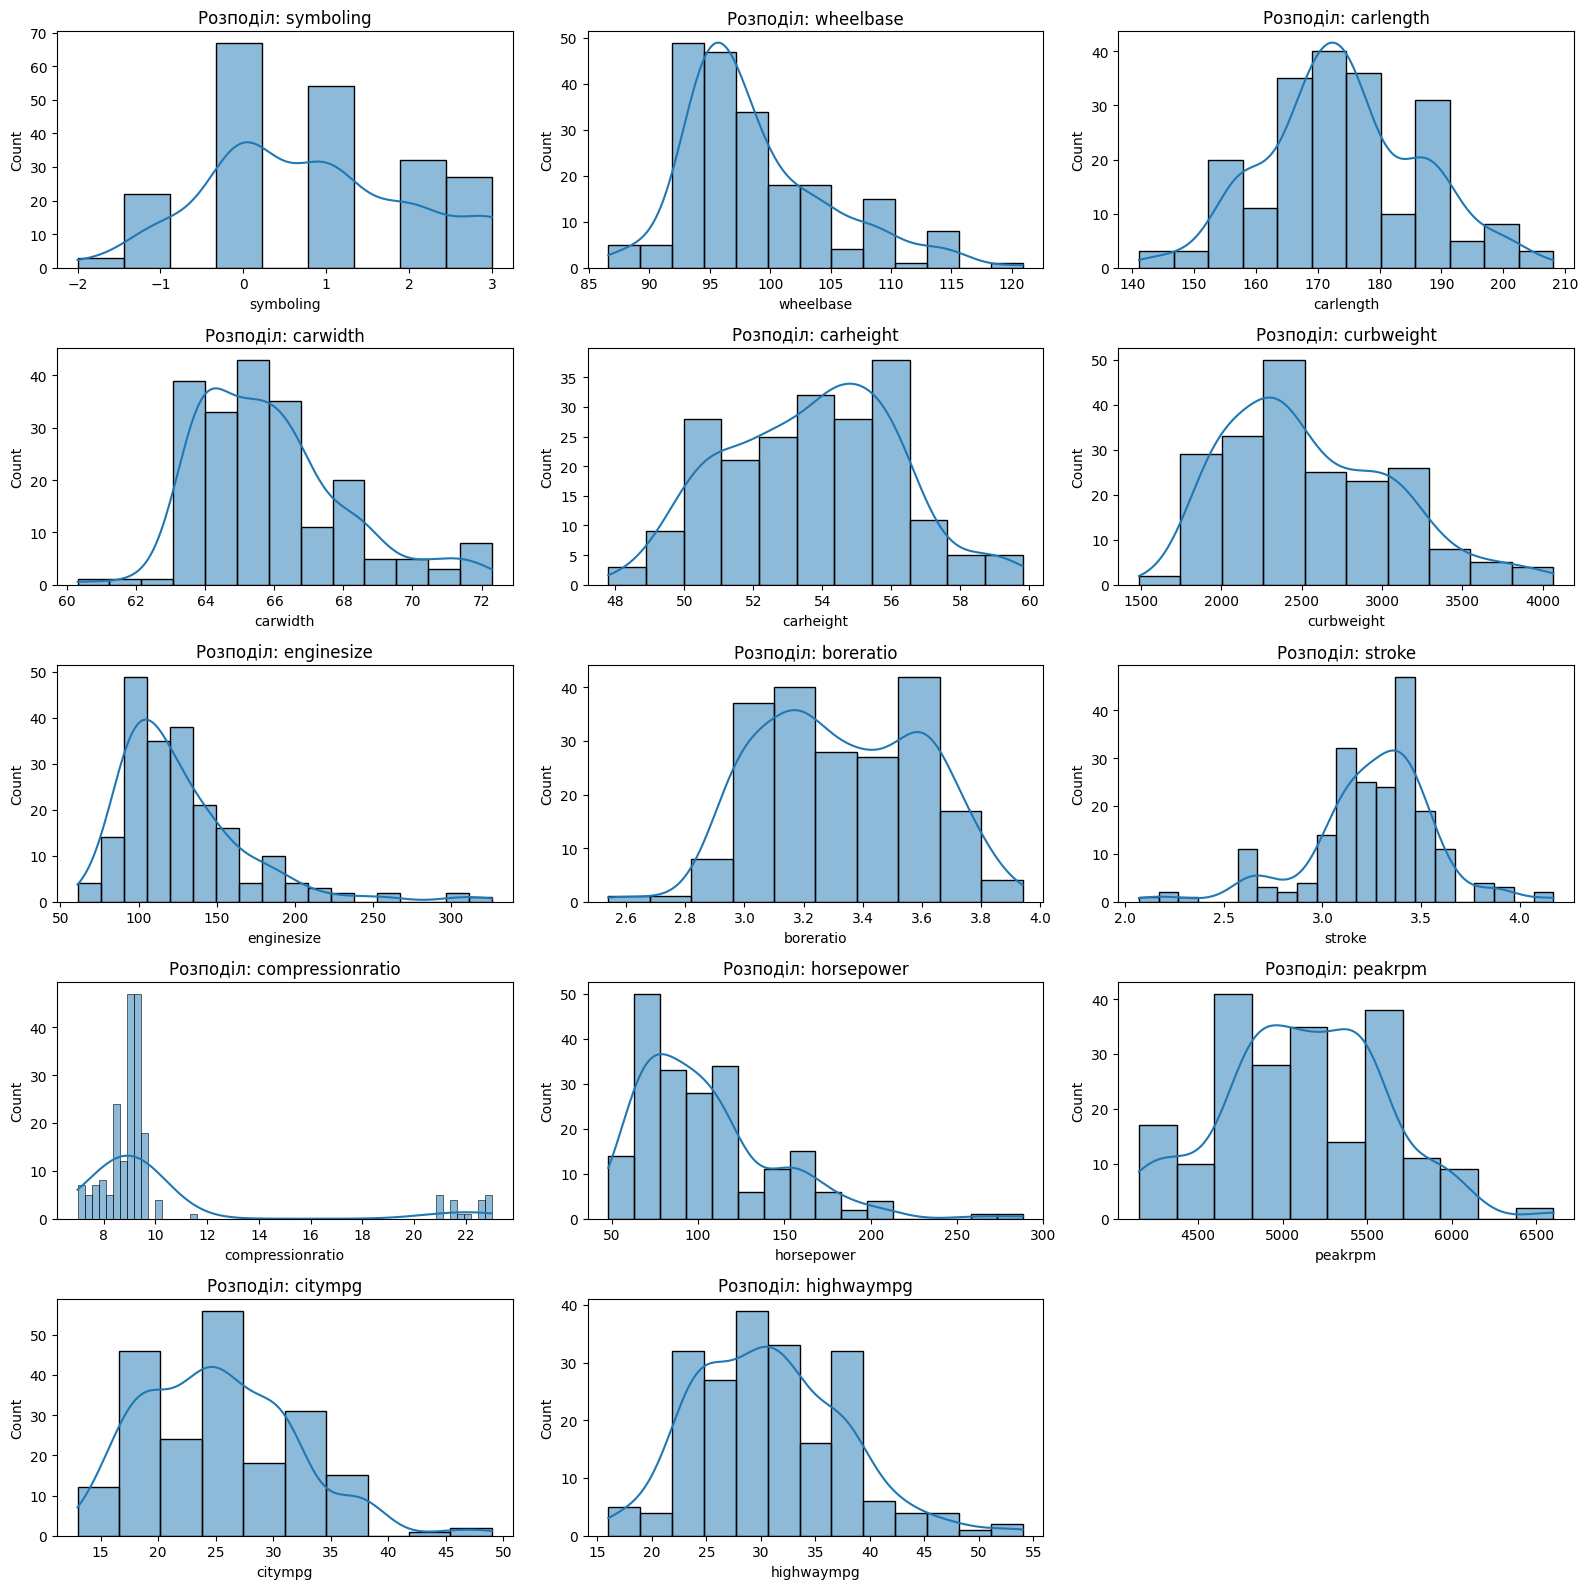

Коефіцієнти асиметрії (за модулем, від більшого до меншого):


,Асиметрія
compressionratio,2.610862
enginesize,1.947655
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003
stroke,-0.689705
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997
symboling,0.211072


Найбільш асиметричні ознаки:


,Асиметрія
compressionratio,2.610862
enginesize,1.947655
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003


In [6]:
numeric_cols_all = data.select_dtypes(include=np.number).columns.tolist()
numeric_cols_for_plot = [c for c in numeric_cols_all if c != "price"]

n_cols = 3
n_rows = int(np.ceil(len(numeric_cols_for_plot) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, max(4, n_rows * 3.2)))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, numeric_cols_for_plot):
    sns.histplot(data=data, x=col, kde=True, ax=ax)
    ax.set_title(f"Розподіл: {col}")
for ax in axes[len(numeric_cols_for_plot):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

skewness = data[numeric_cols_for_plot].skew(numeric_only=True).sort_values(
    key=lambda s: s.abs(), ascending=False
)
print("Коефіцієнти асиметрії (за модулем, від більшого до меншого):")
display(skewness.rename("Асиметрія").to_frame())
if len(skewness):
    print("Найбільш асиметричні ознаки:")
    display(skewness.head(5).rename("Асиметрія").to_frame())

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [7]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=["price"]).copy()
y = data["price"].copy()
ids = car_ids.loc[data.index].copy()

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, ids, test_size=0.20, random_state=42
)
print(f"Train: {X_train.shape[0]} рядків; Test: {X_test.shape[0]} рядків.")
print(f"Ознаки на вході: {X_train.shape[1]}; car_ID не входить до X.")
print(f"Діапазон car_ID у train: {id_train.min()}–{id_train.max()}")
print(f"Діапазон car_ID у test: {id_test.min()}–{id_test.max()}")

Train: 164 рядків; Test: 41 рядків.
Ознаки на вході: 24; car_ID не входить до X.
Діапазон car_ID у train: 1–205
Діапазон car_ID у test: 10–203


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [8]:
continuous_candidate_cols = [
    c for c in X_train.select_dtypes(include=np.number).columns if c != "symboling"
]
iqr_bounds = {}
outlier_rows = []
for col in continuous_candidate_cols:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    iqr_bounds[col] = (lower, upper)
    count = int(((X_train[col] < lower) | (X_train[col] > upper)).sum())
    outlier_rows.append({"Ознака": col, "Нижня межа": lower, "Верхня межа": upper,
                         "Кількість потенційних викидів": count})

outlier_table = pd.DataFrame(outlier_rows).sort_values(
    "Кількість потенційних викидів", ascending=False
)
display(outlier_table)

X_train_clipped = X_train.copy()
X_test_clipped = X_test.copy()
for col, (lower, upper) in iqr_bounds.items():
    X_train_clipped[col] = X_train_clipped[col].clip(lower, upper)
    X_test_clipped[col] = X_test_clipped[col].clip(lower, upper)

,Ознака,Нижня межа,Верхня межа,Кількість потенційних викидів
8,compressionratio,7.4000,10.6000,20
7,stroke,2.6600,3.8600,16
2,carwidth,60.4250,70.4250,10
9,horsepower,4.7500,182.7500,7
5,enginesize,33.5000,205.5000,7
0,wheelbase,83.1000,113.5000,6
10,peakrpm,3750.0000,6550.0000,2
12,highwaympg,11.5000,47.5000,1
6,boreratio,2.5650,4.1250,1
4,curbweight,998.6250,4103.6250,0


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


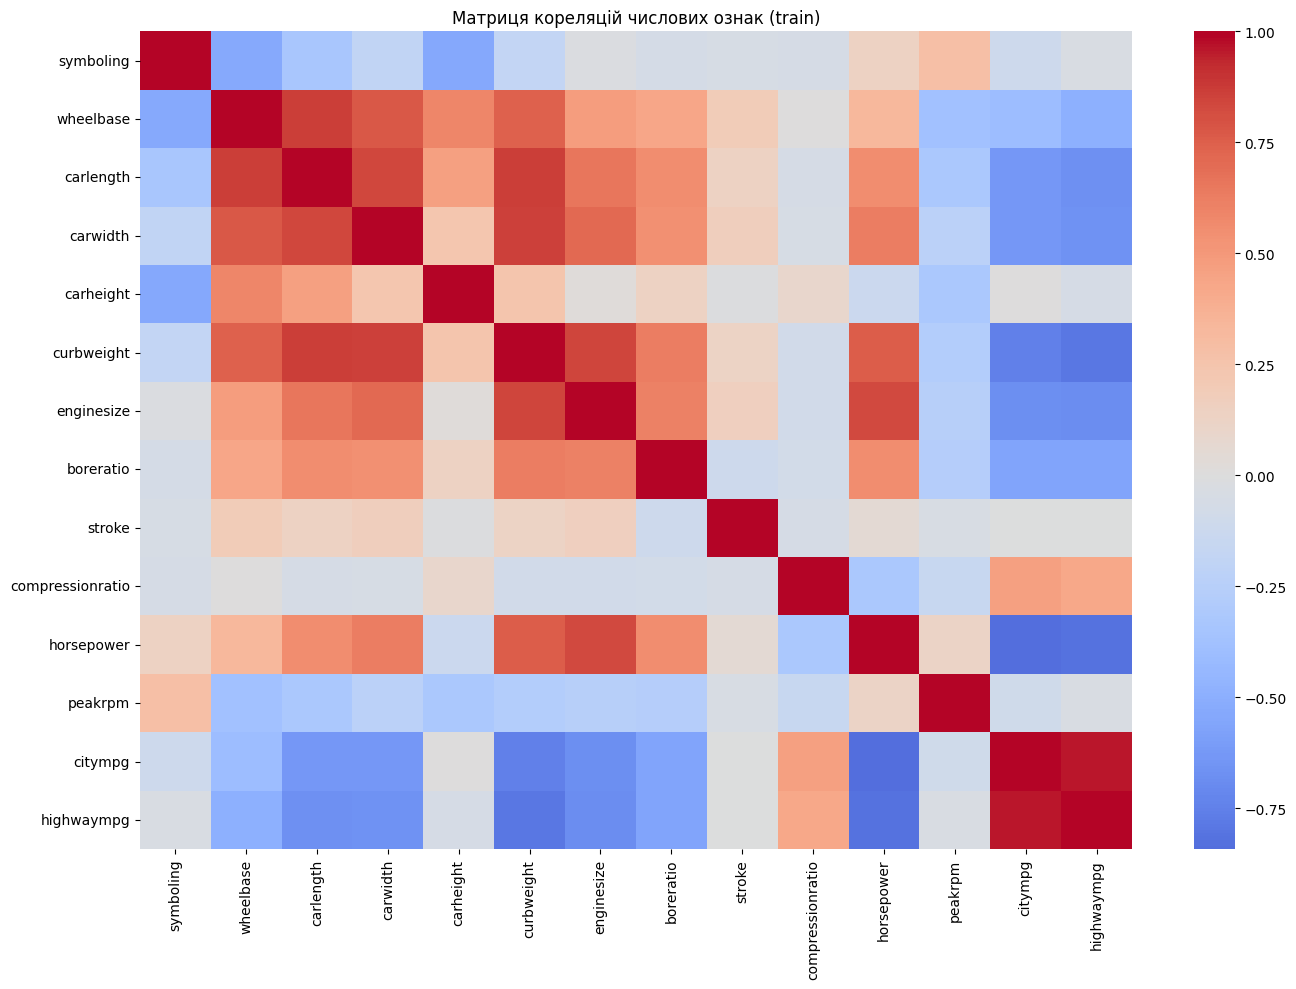

Пари ознак із |r| > 0.85:


,Ознака 1,Ознака 2,Кореляція r,|corr з price| ознаки 1,|corr з price| ознаки 2
0,wheelbase,carlength,0.867043,0.504036,0.652071
1,carlength,curbweight,0.865988,0.652071,0.824212
2,carwidth,curbweight,0.858047,0.731623,0.824212
3,citympg,highwaympg,0.963620,0.711245,0.716460


Ознаки, відібрані для вилучення: ['carlength', 'carwidth', 'citympg', 'wheelbase']
Кількість ознак до відбору: 24
Кількість ознак після відбору: 20


In [9]:
numeric_train = X_train_clipped.select_dtypes(include=np.number)
corr_matrix = numeric_train.corr()
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, annot=False)
plt.title("Матриця кореляцій числових ознак (train)")
plt.tight_layout()
plt.show()

target_corr = X_train_clipped.select_dtypes(include=np.number).corrwith(y_train).abs()
strong_pairs = []
cols = corr_matrix.columns.tolist()
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        r = corr_matrix.iloc[i, j]
        if pd.notna(r) and abs(r) > 0.85:
            a, b = cols[i], cols[j]
            strong_pairs.append({
                "Ознака 1": a, "Ознака 2": b, "Кореляція r": r,
                "|corr з price| ознаки 1": target_corr.get(a, np.nan),
                "|corr з price| ознаки 2": target_corr.get(b, np.nan)
            })

strong_pairs_df = pd.DataFrame(strong_pairs)
to_drop = set()
if not strong_pairs_df.empty:
    for _, row in strong_pairs_df.iterrows():
        a, b = row["Ознака 1"], row["Ознака 2"]
        if a in to_drop or b in to_drop:
            continue
        ca, cb = target_corr.get(a, 0), target_corr.get(b, 0)
        to_drop.add(b if ca >= cb else a)
    print("Пари ознак із |r| > 0.85:")
    display(strong_pairs_df)
else:
    print("Пар із |r| > 0.85 не знайдено.")

print("Ознаки, відібрані для вилучення:", sorted(to_drop) if to_drop else "немає")
X_train_selected = X_train_clipped.drop(columns=list(to_drop), errors="ignore")
X_test_selected = X_test_clipped.drop(columns=list(to_drop), errors="ignore")
print(f"Кількість ознак до відбору: {X_train_clipped.shape[1]}")
print(f"Кількість ознак після відбору: {X_train_selected.shape[1]}")

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

continuous_cols = [
    c for c in X_train_selected.select_dtypes(include=np.number).columns if c != "symboling"
]
symboling_cols = ["symboling"] if "symboling" in X_train_selected.columns else []
categorical_cols = X_train_selected.select_dtypes(exclude=np.number).columns.tolist()

continuous_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=False)),
    ("scaler", StandardScaler())
])
symboling_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []
if continuous_cols:
    transformers.append(("continuous", continuous_pipeline, continuous_cols))
if symboling_cols:
    transformers.append(("symboling", symboling_pipeline, symboling_cols))
if categorical_cols:
    transformers.append(("categorical", categorical_pipeline, categorical_cols))

preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")

print("Неперервні числові ознаки:", continuous_cols)
print("Дискретна числова ознака symboling:", symboling_cols)
print("Категоріальні ознаки:", categorical_cols)

Неперервні числові ознаки: ['carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']
Дискретна числова ознака symboling: ['symboling']
Категоріальні ознаки: ['CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [11]:
if continuous_cols:
    numeric_transformer = continuous_pipeline.fit(X_train_selected[continuous_cols])
    transformed_continuous = numeric_transformer.transform(X_train_selected[continuous_cols])
    transformed_df = pd.DataFrame(transformed_continuous, columns=continuous_cols,
                                  index=X_train_selected.index)
    skew_before = X_train_selected[continuous_cols].skew()
    skew_after = transformed_df.skew()
    skew_comparison = pd.DataFrame({
        "Асиметрія до трансформації": skew_before,
        "Асиметрія після Yeo–Johnson + StandardScaler": skew_after,
        "Зміна абсолютної асиметрії": skew_before.abs() - skew_after.abs()
    })
    display(skew_comparison.sort_values("Зміна абсолютної асиметрії", ascending=False))
    improved = int((skew_after.abs() < skew_before.abs()).sum())
    print(f"Абсолютна асиметрія зменшилася у {improved} із {len(continuous_cols)} ознак.")
else:
    print("Неперервних числових ознак для перевірки немає.")

,Асиметрія до трансформації,Асиметрія після Yeo–Johnson + StandardScaler,Зміна абсолютної асиметрії
enginesize,0.962394,0.044834,0.917560
horsepower,0.850735,0.066280,0.784455
curbweight,0.712433,0.049894,0.662539
stroke,-0.397600,0.015846,0.381754
highwaympg,0.243761,-0.012188,0.231574
boreratio,0.062963,-0.005941,0.057021
compressionratio,0.055710,0.004872,0.050838
peakrpm,0.039773,-0.003589,0.036184
carheight,0.028154,-0.005170,0.022984


Абсолютна асиметрія зменшилася у 9 із 9 ознак.


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [12]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.base import clone

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01, max_iter=20000, random_state=42),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=300, random_state=42, min_samples_leaf=1
    ),
    "Gradient Boosting Regressor": GradientBoostingRegressor(random_state=42),
    "Support Vector Regressor (SVR)": SVR(kernel="rbf", C=100, epsilon=0.1)
}

pipelines = {
    name: Pipeline(steps=[("preprocessor", clone(preprocessor)), ("model", estimator)])
    for name, estimator in models.items()
}
predictions = {}
for name, pipeline in pipelines.items():
    pipeline.fit(X_train_selected, y_train)
    predictions[name] = pipeline.predict(X_test_selected)
    print(f"{name}: модель навчено.")

Linear Regression: модель навчено.
Ridge Regression: модель навчено.
Lasso Regression: модель навчено.
Random Forest Regressor: модель навчено.
Gradient Boosting Regressor: модель навчено.
Support Vector Regressor (SVR): модель навчено.


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [13]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

results = []
for name, y_pred in predictions.items():
    results.append({
        "Модель": name,
        "R²": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "MAPE, %": np.mean(np.abs((y_test.to_numpy() - y_pred) /
                                  np.maximum(np.abs(y_test.to_numpy()), 1e-8))) * 100
    })

results_df = pd.DataFrame(results).sort_values("R²", ascending=False).reset_index(drop=True)
display(results_df.style.format({
    "R²": "{:.4f}", "MAE": "{:,.2f}", "MSE": "{:,.2f}", "MAPE, %": "{:.2f}%"
}))

best_r2 = results_df.iloc[0]
best_mae = results_df.loc[results_df["MAE"].idxmin()]
best_mse = results_df.loc[results_df["MSE"].idxmin()]
best_mape = results_df.loc[results_df["MAPE, %"].idxmin()]
print(f"Найвище R²: {best_r2['Модель']} ({best_r2['R²']:.4f}).")
print(f"Найменше MAE: {best_mae['Модель']} ({best_mae['MAE']:.2f}).")
print(f"Найменше MSE: {best_mse['Модель']} ({best_mse['MSE']:.2f}).")
print(f"Найменше MAPE: {best_mape['Модель']} ({best_mape['MAPE, %']:.2f}%).")

train_test_r2 = []
for name, pipeline in pipelines.items():
    train_pred = pipeline.predict(X_train_selected)
    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, predictions[name])
    train_test_r2.append({"Модель": name, "R² train": train_r2, "R² test": test_r2,
                          "Різниця train-test": train_r2 - test_r2})
train_test_r2_df = pd.DataFrame(train_test_r2).sort_values("Різниця train-test", ascending=False)
print("\nПеревірка можливого перенавчання (великий розрив train/test може бути його ознакою):")
display(train_test_r2_df.style.format({
    "R² train": "{:.4f}", "R² test": "{:.4f}", "Різниця train-test": "{:.4f}"
}))

,Модель,R²,MAE,MSE,"MAPE, %"
0,Random Forest Regressor,0.9509,"1,424.40","3,873,485.24",10.34%
1,Gradient Boosting Regressor,0.9296,"1,684.46","5,560,429.73",12.59%
2,Ridge Regression,0.7957,"2,712.78","16,129,429.82",23.06%
3,Linear Regression,0.5480,"4,078.29","35,678,836.25",29.97%
4,Lasso Regression,0.4975,"4,056.10","39,669,848.17",28.53%
5,Support Vector Regressor (SVR),0.1075,"4,578.15","70,456,877.60",25.86%


Найвище R²: Random Forest Regressor (0.9509).
Найменше MAE: Random Forest Regressor (1424.40).
Найменше MSE: Random Forest Regressor (3873485.24).
Найменше MAPE: Random Forest Regressor (10.34%).

Перевірка можливого перенавчання (великий розрив train/test може бути його ознакою):


,Модель,R² train,R² test,Різниця train-test
2,Lasso Regression,0.9928,0.4975,0.4953
0,Linear Regression,0.9928,0.5480,0.4448
1,Ridge Regression,0.9619,0.7957,0.1662
4,Gradient Boosting Regressor,0.9921,0.9296,0.0626
3,Random Forest Regressor,0.9854,0.9509,0.0345
5,Support Vector Regressor (SVR),0.1244,0.1075,0.0169


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Прогнозування price є задачею регресії, оскільки цільова змінна - числова й може набувати багатьох неперервних значень. Logistic Regression зазвичай застосовується для класифікації: вона оцінює ймовірність належності об'єкта до класу, а не безпосередньо прогнозує довільну ціну автомобіля. Щоб застосувати класифікацію, ціну довелося б попередньо перетворити на категорії, через що втрачалася б точність конкретного числового прогнозу.
Linear Regression, Ridge, Lasso, Random Forest Regressor, Gradient Boosting Regressor і SVR у використаних конфігураціях підтримують регресійне прогнозування числової цілі, тому відповідають поставленій задачі.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


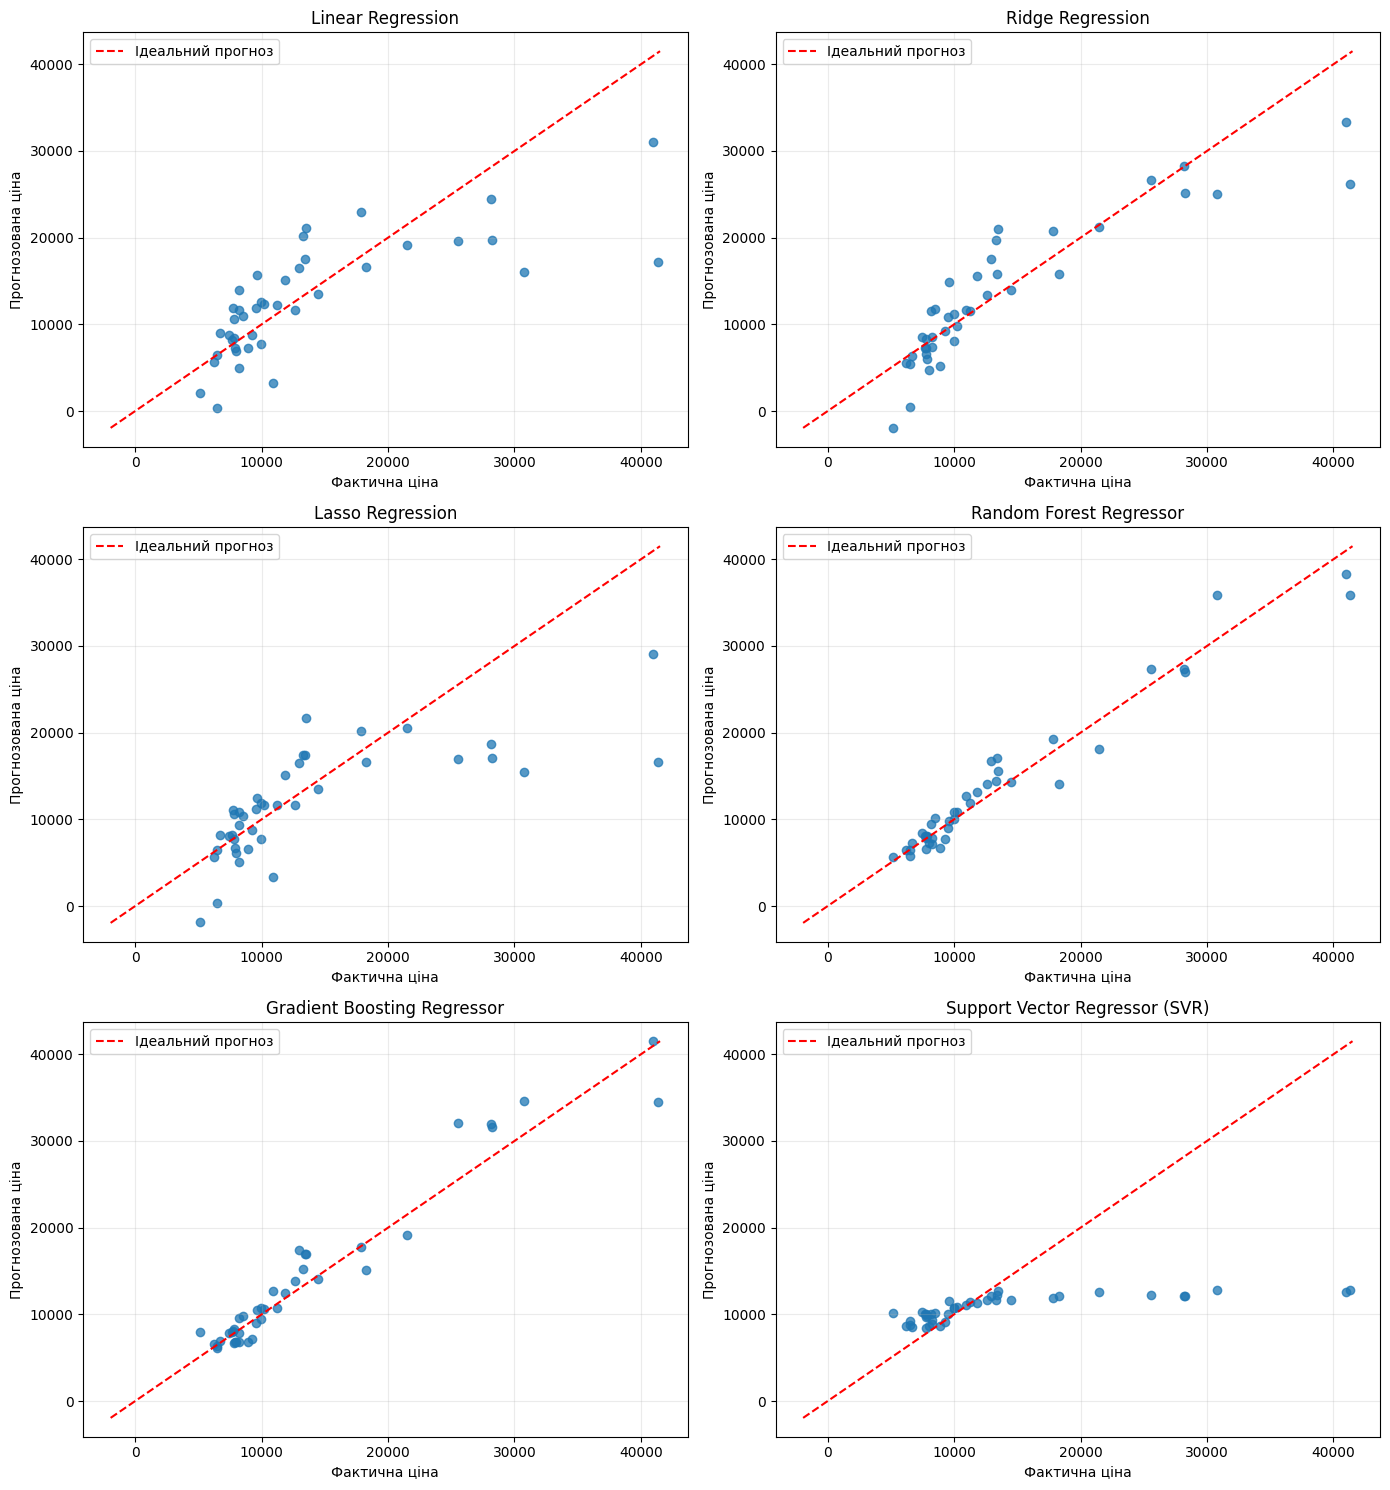

In [14]:
n_models = len(predictions)
ncols = 2
nrows = int(np.ceil(n_models / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 5 * nrows))
axes = np.array(axes).reshape(-1)

y_true_arr = y_test.to_numpy()
low = min(float(np.min(y_true_arr)), *(float(np.min(p)) for p in predictions.values()))
high = max(float(np.max(y_true_arr)), *(float(np.max(p)) for p in predictions.values()))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_true_arr, y_pred, alpha=0.75)
    ax.plot([low, high], [low, high], "r--", label="Ідеальний прогноз")
    ax.set_title(name)
    ax.set_xlabel("Фактична ціна")
    ax.set_ylabel("Прогнозована ціна")
    ax.legend()
    ax.grid(alpha=0.25)
for ax in axes[n_models:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [15]:
rng = np.random.default_rng(42)
sample_size = min(10, len(X_test_selected))
sample_positions = rng.choice(len(X_test_selected), size=sample_size, replace=False)
X_sample = X_test_selected.iloc[sample_positions]
y_sample = y_test.iloc[sample_positions]
id_sample = id_test.iloc[sample_positions]
rf_pipeline = pipelines["Random Forest Regressor"]
sample_pred = rf_pipeline.predict(X_sample)

sample_results = pd.DataFrame({
    "car_ID": id_sample.to_numpy(),
    "Фактична ціна": y_sample.to_numpy(),
    "Прогнозована ціна": sample_pred,
})
sample_results["Абсолютна помилка"] = (
    sample_results["Фактична ціна"] - sample_results["Прогнозована ціна"]
).abs()
sample_results["Абсолютна відсоткова помилка, %"] = (
    sample_results["Абсолютна помилка"] /
    sample_results["Фактична ціна"].abs().clip(lower=1e-8) * 100
)
display(sample_results.style.format({
    "Фактична ціна": "{:,.2f}",
    "Прогнозована ціна": "{:,.2f}",
    "Абсолютна помилка": "{:,.2f}",
    "Абсолютна відсоткова помилка, %": "{:.2f}%"
}))

print(f"Середня абсолютна помилка для вибраних автомобілів: {sample_results['Абсолютна помилка'].mean():.2f}")
print(f"Середня абсолютна відсоткова помилка: {sample_results['Абсолютна відсоткова помилка, %'].mean():.2f}%")
worst = sample_results.loc[sample_results["Абсолютна помилка"].idxmax()]
print(
    f"Найбільша абсолютна помилка в цій вибірці у car_ID={int(worst['car_ID'])}: "
    f"{worst['Абсолютна помилка']:.2f}."
)

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,"Абсолютна відсоткова помилка, %"
0,133,"11,850.00","13,192.80","1,342.80",11.33%
1,17,"41,315.00","35,845.66","5,469.34",13.24%
2,101,"9,549.00","9,037.97",511.03,5.35%
3,99,"8,249.00","7,114.56","1,134.44",13.75%
4,153,"6,488.00","6,467.80",20.20,0.31%
5,70,"28,176.00","27,378.19",797.81,2.83%
6,196,"13,415.00","17,055.39","3,640.39",27.14%
7,147,"7,463.00","8,422.47",959.47,12.86%
8,148,"10,198.00","10,871.77",673.77,6.61%
9,121,"6,229.00","6,446.90",217.90,3.50%


Середня абсолютна помилка для вибраних автомобілів: 1476.72
Середня абсолютна відсоткова помилка: 9.69%
Найбільша абсолютна помилка в цій вибірці у car_ID=17: 5469.34.


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


Найвище значення R² указує на кращу пояснену частку варіації ціни, а нижчі MAE, MSE і MAPE - на менші помилки прогнозування. Ураховуйте всі метрики разом: MSE сильніше реагує на великі похибки, а MAPE показує середню відносну похибку у відсотках.
Зверніть увагу на таблицю R² train і R² test: значно вищий результат на train порівняно з test може свідчити про перенавчання. Попередня обробка забезпечує обмеження викидів за межами, визначеними лише на train, відбір сильно корельованих ознак, трансформацію та масштабування числових даних і кодування категорій. Остаточний висновок про найкращу модель потрібно сформулювати за фактичними результатами, отриманими після запуску ноутбука.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
